# Lecture: Clinical Research Informatics - Sommer Semester 2026
Exercise Sheet: {09}
Student Name: {David_Jansen}
Matriculation Number: {657442}
   
Additional information:   
used additional packages: {Package name and version}   
dataset used: {dataset or file name}   

In [1]:
# Please add this header to all your submissions and adapt it to your information and submission.
# The following structure is a recommendation, but not mandatory to use

# Functions

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Section 1

1.1

Original describe:
                                           Id   BIRTHDATE   DEATHDATE  \
count                                    327         327           4   
unique                                   327         306           4   
top     2e88d207-95b7-2ea8-ea61-b9f843bdfa91  2016-05-07  2021-05-20   
freq                                       1           4           1   
mean                                     NaN         NaN         NaN   
std                                      NaN         NaN         NaN   
min                                      NaN         NaN         NaN   
25%                                      NaN         NaN         NaN   
50%                                      NaN         NaN         NaN   
75%                                      NaN         NaN         NaN   
max                                      NaN         NaN         NaN   

                SSN  DRIVERS  PASSPORT  PREFIX       FIRST          LAST  \
count           327      0.0       0.0 

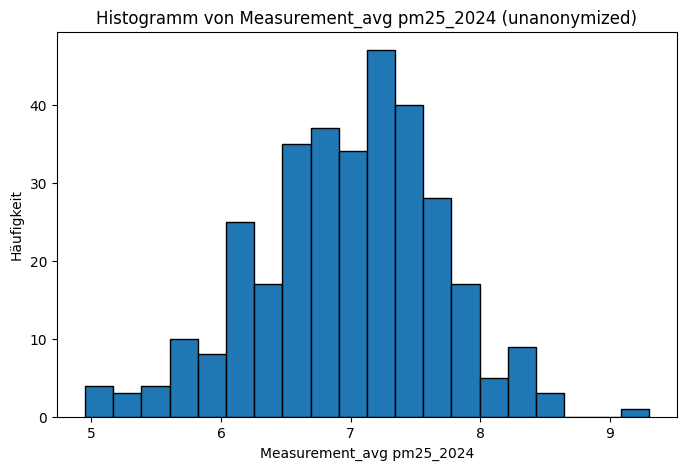

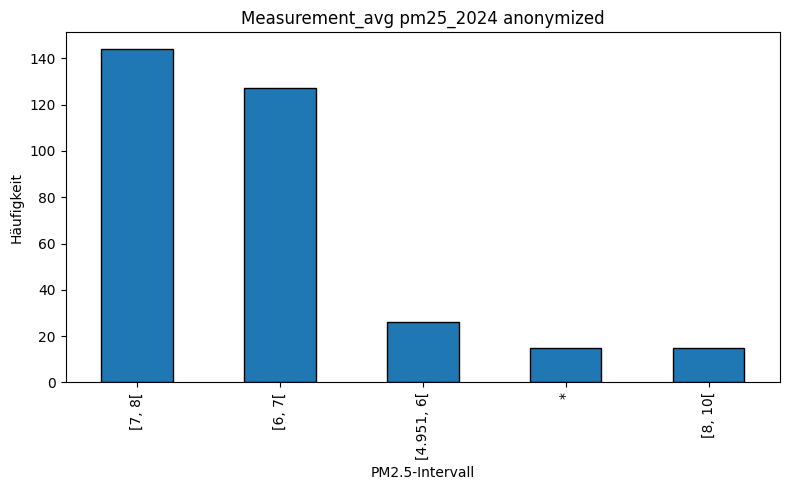

In [3]:
unanonymized_data = pd.read_csv("week_6_data.csv")
anonymized_data = pd.read_csv("hu-assignment-08-example-anonymized.csv")

desc_orig = unanonymized_data.describe(include="all")
desc_anon = anonymized_data.describe(include="all")

print("Original describe:\n", desc_orig)
print("\nAnonymized describe:\n", desc_anon)

col = "Measurement_avg pm25_2024"  # exakt wie in df.columns

# Falls die Werte als Strings vorliegen: in Zahlen konvertieren
values = pd.to_numeric(unanonymized_data[col], errors="coerce").dropna()

plt.figure(figsize=(8, 5))
plt.hist(values, bins=20, edgecolor="black")  # bins nach Bedarf ändern
plt.title("Histogramm von Measurement_avg pm25_2024 (unanonymized)")
plt.xlabel("Measurement_avg pm25_2024")
plt.ylabel("Häufigkeit")

cats = anonymized_data["Measurement_avg pm25_2024"].dropna().value_counts()

import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
cats.plot(kind="bar", edgecolor="black")
plt.title("Measurement_avg pm25_2024 anonymized")
plt.xlabel("PM2.5-Intervall")
plt.ylabel("Häufigkeit")

plt.tight_layout()
plt.show()

- There are no real outliers because they are supressed or mapped into a range of numbers becuase of anonymization
- Distribution is way closer, it has fewer categories due to generalization

also see CRI_Exercise_9_Jansen.pdf


2.1

In [4]:
measurement_orig = unanonymized_data["Measurement_avg pm25_2024"]
asthma_orig = unanonymized_data["ASTHMA_REASON_ENCOUNTER"]
r_measurement_orig = measurement_orig.rank(method="average")
r_asthma_orig = asthma_orig.rank(method="average")

r_orig = np.corrcoef(r_measurement_orig, r_asthma_orig)[0, 1]
print("Spearman r (unanonymized):", r_orig)

n_orig = len(unanonymized_data.dropna(subset=["Measurement_avg pm25_2021", "ASTHMA_REASON_ENCOUNTER"]))
t_orig = r_orig * np.sqrt((n_orig - 2) / (1 - r_orig**2))
df_orig = n_orig - 2
print("t-Wert (unanonymized):", t_orig)
print("df (unanonymized):", df_orig)



measurement_anon = anonymized_data["Measurement_avg pm25_2024"]
asthma_anon = anonymized_data["ASTHMA_REASON_ENCOUNTER"]
r_measurement_anon = measurement_anon.rank(method="average")
r_asthma_anon = asthma_anon.rank(method="average")

r_anon = np.corrcoef(r_measurement_anon, r_asthma_anon)[0, 1]
print("Spearman r (anonymized):", r_anon)

n_anon = len(anonymized_data.dropna(subset=["Measurement_avg pm25_2021", "ASTHMA_REASON_ENCOUNTER"]))
t_anon = r_anon * np.sqrt((n_anon - 2) / (1 - r_anon**2))
df_anon = n_anon - 2
print("t-Wert (anonymized):", t_anon)
print("df (anonymized):", df_anon)



Spearman r (unanonymized): 0.4570366649302343
t-Wert (unanonymized): 9.263438664550138
df (unanonymized): 325
Spearman r (anonymized): 0.5233499624851611
t-Wert (anonymized): 11.072207572710447
df (anonymized): 325
